# Set Up


In [1]:
# import
import anndata as ad
import geopandas as gpd
import numpy as np
import pandas as pd
import random
import scanpy as sc
import scipy.sparse as sp
import squidpy as sq
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from plyer import notification
from sklearn.preprocessing import StandardScaler
from torch_geometric.data import Data
from torch_geometric.loader import NeighborLoader
from torch_geometric.nn import SAGEConv
from torch_geometric.nn import TransformerConv


/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dual autoencoder for histology <-> spatial transcriptomics alignment.
 
#### WHAT CHANGED VS. THE PREVIOUS VERSION
--------------------------------------
1. Hierarchical contrastive alignment (main structural change):
       GraphSAGE -> cell latents -> pool within patch -> patch latent -> contrastive loss
   Reconstruction still happens at the CELL level (preserves cell-type heterogeneity).
   Contrastive alignment now happens at the PATCH level, where the histology <-> patch
   correspondence is genuinely one-to-one, instead of broadcasting one patch embedding
   to every nucleus and contrasting at the cell level.
 
2. Patch-grouped mini-batching. Plain node-level NeighborLoader batches contain an
   arbitrary, uneven number of cells per patch, which makes patch-level pooling
   meaningless for patches barely represented in a batch. `PatchGroupedLoader` below
   samples whole patches (capped at `max_cells_per_patch` cells each) per batch instead.
 
3. Neighbor-aware patch-level InfoNCE. Standard InfoNCE pushes ALL non-positive
   patches apart equally, which is wrong under spatial autocorrelation: two
   neighboring patches can be genuinely similar in both modalities. We exclude
   spatially close, non-matching patches from the negative set (`neighbor_radius`)
   rather than forcing them apart. Evaluation also reports a neighborhood-tolerant
   retrieval accuracy alongside strict top-1, for the same reason.
 
4. Standardization of both modalities (z-score) before training.
 
5. Inverse-frequency weighting of patches, applied to the patch-level contrastive
   loss and (optionally) to the per-cell reconstruction loss, so that patches with
   many sampled cells don't dominate purely due to sampling variance. This also
   fixes a subtler issue in the old code: broadcasting one patch embedding to every
   nucleus meant a patch appearing more often in a batch acted as a "louder"
   negative for everyone else, independent of biology.
 
6. Explicit patch-level metadata table (`patch_meta`) tracking Patch_ID, Slide_ID,
   spatial centroid, cell count, and derived weight, saved alongside the model /
   latents for downstream analysis.
 
#### ASSUMPTIONS YOU SHOULD VERIFY AGAINST YOUR ACTUAL DATA
-------------------------------------------------------
- `nuclei_geometry.parquet` has a `geometry` column (point geometries) and either
  shares its index with `trans_adata.obs` or has an `id` column matching it. This is
  only used to compute patch centroids (for the neighbor-aware masking and the
  metadata table) -- adjust `extract_cell_xy()` if your schema differs.
- Patch centroids are computed as the mean nucleus position per patch. If you
  already have a patch centroid elsewhere (e.g. in `hist_adata.obs`), prefer that
  instead -- it'll be more accurate than averaging nuclei positions.
"""


In [2]:
def set_seed(seed: int = 42):
    """Set random seeds across all dependencies for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # for multi-GPU setups
    
    # Enforce deterministic algorithm behavior in PyTorch/cuDNN
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [3]:
# confiuration

# NOTE to self: parameters to test and compare
# - ntxent vs cosine loss
# attention pooling vs mean
# sage vs transconv
# obvs test temp, epochs, lr, warumup, max contrast weight
# test HVG vs SVG vs combo vs PCA?

CONFIG = dict(
    sample="all",     # str -> single slide. list[str] or "all" -> multi-slide.
    bin_size="002um",
    dir_cellseg="cell_seg_stardist",  # in case of multiple cell segmentation methods
    loss_fct="ntxent",                # optional: ntxent, cosine
 
    # model
    latent_dim=64,
    proj_dim=32,
    pool_type="attention",            # "attention" or "mean"
    encoder="sage",                   # sage or transconv for transcriptomics encoding
 
    # graph / batching
    n_neighs=6,                       # spatial neighbor graph degree
    num_neighbors=(10, 10),           # GraphSAGE neighbor sampling fanout
    patches_per_batch=16,             # patches per mini-batch (NEW: patch-grouped batching)
    max_cells_per_patch=64,           # cap cells/patch per batch (memory control)
 
    # loss
    temperature=0.07,
    neighbor_radius=None,             # set to a real distance in your coordinate units to enable
                                       # neighbor-aware negative masking, e.g. 2-3x patch diameter
    weight_reconstruction_by_patch_freq=True,   # apply inverse-frequency weight to cell recon loss too
 
    # training
    n_epochs=30,
    lr=1e-3,
    warmup_epochs=5,
    max_contrast_weight=1.0,
)
 
xpca_hist = False
xpca_trans = False
xpca_col_hist = "X_pca"
xpca_col_trans = "X_pca"


In [4]:
basedir = Path("../../data")
dir_histology = basedir / "combined/01_preprocessing/unimodel/metadata"
dir_transcriptomics = basedir / "combined/01_preprocessing" / CONFIG["dir_cellseg"] / CONFIG["bin_size"] / "custom_binning"
_run_tag = CONFIG["sample"] if isinstance(CONFIG["sample"], str) else "combined"
dir_output = basedir / _run_tag / "03_integration/autoencoders" / CONFIG["bin_size"]
dir_output.mkdir(parents=True, exist_ok=True)

# Data Prepatation Functions

In [5]:
def finish_note():
    from plyer import notification
    notification.notify(
        title='Jupyter Notebook Alert',
        message='Your script has finished running!',
        app_name='Jupyter',
        timeout=5 # Notification disappears after 5 seconds
    )

def get_svg_union_mask(trans_adata, per_sample_key="spatially_variable_per_sample"):
    """Union across samples: gene is an SVG if flagged in >=1 sample."""
    if per_sample_key in trans_adata.varm:
        sv = np.asarray(trans_adata.varm[per_sample_key]).astype(bool)
        return sv.any(axis=1)
    return (trans_adata.var["spatially_variable_n_samples"] >= 1).values
 
 
def build_spatial_graph(trans_adata, library_key="Slide_ID", n_neighs=6, delaunay=False, percentile=95.0):
    """Uses squidpy so that neighbors are only ever formed within a sample."""
    
    if delaunay:
        # Delaunay triangulation within each library slide
        sq.gr.spatial_neighbors_delaunay(
            trans_adata,
            spatial_key="spatial",
            library_key=library_key,
            percentile=percentile,  # Prunes long Delaunay edges beyond 95th percentile distance
        )
    else:
        # KNN graph within each library slide
        sq.gr.spatial_neighbors_knn(
            trans_adata,
            spatial_key="spatial",
            library_key=library_key,
            n_neighs=n_neighs,
        )

    # Extract connectivity matrix
    conn = trans_adata.obsp["spatial_connectivities"]
    
    # Verify no cross-sample edges were formed
    slide_ids = trans_adata.obs[library_key].values
    coo = conn.tocoo()
    cross = (slide_ids[coo.row] != slide_ids[coo.col]).sum()
    assert cross == 0, f"Found {cross} cross-sample edges - check library_key"
    
    return conn
 
 
def build_pairing(trans_adata, hist_adata, trans_patch_col="Patch_ID", hist_patch_col="Patch_ID",
                   slide_col="Slide_ID"):
    """
    Returns:
      keep_mask: (n_trans,) bool array, nuclei with a matching histology patch
      patch_row_trans: (n_kept,) int array, which unique histology-patch row each
                        kept nucleus belongs to
      hist_emb: (n_unique_patches, hist_dim) float32 array, one row per unique patch
    """
    trans_key = (
        trans_adata.obs[slide_col].astype(str) + "_" + trans_adata.obs[trans_patch_col].astype(str)
    )
    hist_key = (
        hist_adata.obs[slide_col].astype(str) + "_" + hist_adata.obs[hist_patch_col].astype(str)
    )
    assert hist_key.is_unique, "hist.obs has duplicate Slide_ID+Patch_ID rows"
 
    key_to_hist_row = {k: i for i, k in enumerate(hist_key)}
 
    missing = ~trans_key.isin(key_to_hist_row)
    if missing.any():
        print(f"WARNING: {missing.sum()} / {len(trans_key)} nuclei have no matching "
              f"hist patch - dropping them.")
    keep_mask = ~missing.values
 
    patch_key_trans = trans_key.values[keep_mask]
    patch_row_trans = np.array([key_to_hist_row[k] for k in patch_key_trans])
 
    hist_X = hist_adata.X
    hist_emb = hist_X.toarray() if sp.issparse(hist_X) else np.asarray(hist_X)
    hist_emb = hist_emb.astype(np.float32)
 
    return keep_mask, patch_row_trans, hist_emb
 
 
def standardize_modalities(X_svg, hist_emb):
    """
    Z-score both modalities before training.
 
    As written, this fits ONE global scaler across whatever cells/patches you pass
    in. With a single slide that's unambiguous. With multiple slides passed in at
    once, this pools all slides into one mean/std -- fine if you want batch effects
    between slides to remain part of the signal, but if slides differ a lot in
    intensity/exposure/staining, a global scaler can let one slide's scale dominate.
    If that's a concern, standardize per-slide instead (compute mean/std within each
    Slide_ID group, subtract/divide per-group) before concatenating, or pass a
    `groups` array here and extend this function accordingly. If you later add a
    held-out validation slide, fit the scaler on training slides only and
    `.transform()` (never `.fit_transform()`) the held-out one.
    """
    svg_scaler = StandardScaler()
    X_svg_std = svg_scaler.fit_transform(X_svg).astype(np.float32)
 
    hist_scaler = StandardScaler()
    hist_emb_std = hist_scaler.fit_transform(hist_emb).astype(np.float32)
 
    return X_svg_std, hist_emb_std, svg_scaler, hist_scaler
 

def extract_cell_xy(trans_sub, f_trans_coord=None):
    """
    Extracts (N, 2) array of (x, y) cell centroids aligned with `trans_sub.obs_names`.
    
    Priority:
    1. trans_sub.obsm['spatial']
    2. f_trans_coord['centroid'] column or geometry
    """
    # Try extracting directly from AnnData .obsm['spatial']
    if "spatial" in trans_sub.obsm:
        xy = np.asarray(trans_sub.obsm["spatial"], dtype=np.float32)
        if xy.shape[0] == trans_sub.n_obs and xy.shape[1] == 2:
            return xy

    # Fall back to f_trans_coord if provided
    if f_trans_coord is not None:
        coords = f_trans_coord.copy()
        
        # Ensure proper index alignment
        if "id" in coords.columns:
            coords = coords.set_index(coords["id"].astype(str))
        
        # Subset & align order to match trans_sub
        coords = coords.loc[trans_sub.obs_names]
        
        # Check if 'centroid' column exists
        if "centroid" in coords.columns:
            # If centroid column contains Shapely Points
            if hasattr(coords["centroid"], "x"):
                x_vals = coords["centroid"].x.values
                y_vals = coords["centroid"].y.values
            else:
                # If centroid is a column of tuple/list/array objects or Shapely objects
                centroids = coords["centroid"].values
                x_vals = [p.x if hasattr(p, "x") else p[0] for p in centroids]
                y_vals = [p.y if hasattr(p, "y") else p[1] for p in centroids]
            return np.column_stack([x_vals, y_vals]).astype(np.float32)
            
        # Fall back to computing centroid from polygon geometry column
        elif hasattr(coords, "geometry") and coords.geometry is not None:
            centroids = coords.geometry.centroid
            return np.column_stack([centroids.x.values, centroids.y.values]).astype(np.float32)

    # Raise error if no spatial information could be resolved
    raise ValueError(
        "Could not extract spatial coordinates! "
        "Neither 'spatial' key found in `trans_sub.obsm` nor valid centroids in `f_trans_coord`."
    )
 
 
def compute_patch_metadata(patch_row_trans, cell_xy, hist_adata, key_to_hist_row=None,
                            trans_sub=None, slide_col="Slide_ID", patch_col="Patch_ID",
                            neighbor_radius=None):
    """
    Builds one row of metadata per unique histology patch, aligned by integer
    `patch_row` id (the same id used everywhere else in this script, i.e. row index
    into `hist_emb`). Includes:
      - centroid: mean (x, y) position of nuclei assigned to the patch
      - n_cells: number of paired nuclei
      - weight: inverse-frequency weight (mean-normalized to ~1), for use in both
        the patch-level contrastive loss and (optionally) the cell reconstruction loss
      - slide_id: integer code per patch. IMPORTANT for multi-slide runs: raw
        spatial coordinates are per-slide, and different slides commonly have
        overlapping coordinate ranges (e.g. both indexed from ~(0,0)). A patch on
        slide A and an unrelated patch on slide B can end up with a small
        `cdist` distance purely by coincidence. `slide_id` lets the neighbor-radius
        masking in `patch_level_infonce` require "same slide AND close distance"
        instead of just "close distance", so cross-slide pairs are never
        incorrectly excluded from the negative set.
    Also returns a plain pandas DataFrame version for saving/inspection.
    """
    n_hist_patches = hist_adata.shape[0]
 
    df = pd.DataFrame({
        "patch_row": patch_row_trans,
        "x": cell_xy[:, 0],
        "y": cell_xy[:, 1],
    })
    stats = df.groupby("patch_row").agg(x=("x", "mean"), y=("y", "mean"), n_cells=("x", "size"))
 
    centroid = np.zeros((n_hist_patches, 2), dtype=np.float32)
    n_cells = np.zeros(n_hist_patches, dtype=np.float32)
    centroid[stats.index.values] = stats[["x", "y"]].values
    n_cells[stats.index.values] = stats["n_cells"].values
 
    freq = n_cells / max(n_cells.sum(), 1.0)
    weight = np.zeros(n_hist_patches, dtype=np.float32)
    nonzero = n_cells > 0
    weight[nonzero] = 1.0 / freq[nonzero]
    weight[nonzero] = weight[nonzero] / weight[nonzero].mean()  # normalize so mean weight ~= 1
 
    if slide_col in hist_adata.obs:
        slide_id, _slide_uniques = pd.factorize(hist_adata.obs[slide_col].values)
    else:
        slide_id = np.zeros(n_hist_patches, dtype=np.int64)  # single-slide fallback
 
    meta_tensors = {
        "centroid": torch.tensor(centroid, dtype=torch.float32),
        "n_cells": torch.tensor(n_cells, dtype=torch.float32),
        "weight": torch.tensor(weight, dtype=torch.float32),
        "slide_id": torch.tensor(slide_id, dtype=torch.long),
        "neighbor_radius": neighbor_radius,
    }
 
    meta_df = pd.DataFrame({
        "patch_row": np.arange(n_hist_patches),
        "Patch_ID": hist_adata.obs[patch_col].values if patch_col in hist_adata.obs else None,
        "Slide_ID": hist_adata.obs[slide_col].values if slide_col in hist_adata.obs else None,
        "centroid_x": centroid[:, 0],
        "centroid_y": centroid[:, 1],
        "n_cells": n_cells,
        "weight": weight,
    })
 
    return meta_tensors, meta_df
 
 
def build_pyg_data(X_svg, conn, patch_row_trans, slide_codes):
    edge_index = torch.tensor(np.vstack(conn.tocoo().nonzero()), dtype=torch.long)
    data = Data(
        x=torch.tensor(X_svg, dtype=torch.float32),
        edge_index=edge_index,
    )
    data.patch_row = torch.tensor(patch_row_trans, dtype=torch.long)
    data.slide_code = torch.tensor(slide_codes, dtype=torch.long)
    return data
 
 
def build_patch_to_nodes(patch_row_tensor):
    """dict: global patch_row id -> LongTensor of node indices belonging to that patch."""
    patch_row_np = patch_row_tensor.numpy()
    order = np.argsort(patch_row_np, kind="stable")
    sorted_patches = patch_row_np[order]
    unique_patches, start_idx = np.unique(sorted_patches, return_index=True)
    groups = np.split(order, start_idx[1:])
    return {int(p): torch.tensor(g, dtype=torch.long) for p, g in zip(unique_patches, groups)}
 
 
class PatchGroupedLoader:
    """
    Groups cells by patch so each mini-batch contains complete (or capped) patches,
    instead of the arbitrary partial patches a plain node-level NeighborLoader
    would produce. This makes patch-level pooling and patch-level contrastive
    alignment meaningful.
 
    Internally reuses a NeighborLoader's own subgraph-sampling machinery via its
    `collate_fn`, but we drive the seed-node groups ourselves (one group of patches
    per batch) rather than letting NeighborLoader chunk seed nodes arbitrarily.
 
    NOTE: this relies on PyG's `NeighborLoader`/`NodeLoader.collate_fn(index)` being
    directly callable with an arbitrary index tensor. This is standard in recent PyG
    versions; if your PyG version's internals differ, the fallback is to construct a
    fresh `NeighborLoader(data, input_nodes=seed_nodes, batch_size=len(seed_nodes))`
    per group and take its single batch instead.
    """
 
    def __init__(self, data, patch_to_nodes, num_neighbors=(10, 10),
                 patches_per_batch=16, max_cells_per_patch=64, shuffle=True):
        self.patch_to_nodes = patch_to_nodes
        self.patches = list(patch_to_nodes.keys())
        self.patches_per_batch = patches_per_batch
        self.max_cells_per_patch = max_cells_per_patch
        self.shuffle = shuffle
        
        # --- FIX: Pass torch.arange(data.num_nodes) so all node indices are valid ---
        self._sampler_loader = NeighborLoader(
            data, 
            num_neighbors=list(num_neighbors),
            input_nodes=torch.arange(data.num_nodes), 
            batch_size=1,
        )
 
    def __len__(self):
        return (len(self.patches) + self.patches_per_batch - 1) // self.patches_per_batch
 
    def __iter__(self):
        patches = self.patches.copy()
        if self.shuffle:
            random.shuffle(patches)
        for start in range(0, len(patches), self.patches_per_batch):
            batch_patch_ids = patches[start:start + self.patches_per_batch]
            seed_chunks, local_patch_index = [], []
            for local_idx, p in enumerate(batch_patch_ids):
                nodes = self.patch_to_nodes[p]
                if len(nodes) > self.max_cells_per_patch:
                    perm = torch.randperm(len(nodes))[:self.max_cells_per_patch]
                    nodes = nodes[perm]
                seed_chunks.append(nodes)
                local_patch_index.append(torch.full((len(nodes),), local_idx, dtype=torch.long))
            seed_nodes = torch.cat(seed_chunks)
            batch = self._sampler_loader.collate_fn(seed_nodes)
            # NeighborLoader guarantees seed nodes are the first len(seed_nodes) rows.
            batch.local_patch_index = torch.cat(local_patch_index)
            batch.batch_patch_ids = torch.tensor(batch_patch_ids, dtype=torch.long)
            yield batch
 
 
# ---- segment (group-wise) ops, self-contained (no torch_scatter dependency) ----
 
def segment_sum(src, index, num_segments):
    out_shape = (num_segments,) + tuple(src.shape[1:])
    out = torch.zeros(out_shape, device=src.device, dtype=src.dtype)
    out.index_add_(0, index, src)
    return out
 
 
def segment_mean_pool(z, index, num_segments):
    s = segment_sum(z, index, num_segments)
    counts = segment_sum(torch.ones(z.shape[0], 1, device=z.device, dtype=z.dtype), index, num_segments)
    return s / counts.clamp(min=1.0)
 
 
def segment_softmax(scores, index, num_segments):
    seg_max = torch.full((num_segments,), float("-inf"), device=scores.device, dtype=scores.dtype)
    seg_max.scatter_reduce_(0, index, scores, reduce="amax", include_self=True)
    scores = scores - seg_max[index]
    exp_scores = scores.exp()
    seg_sum = segment_sum(exp_scores, index, num_segments)
    return exp_scores / (seg_sum[index] + 1e-12)
 
 
# ---- loss ----
 
def patch_level_infonce(p_trans, p_hist, centroids, slide_ids=None, temperature=0.07,
                         neighbor_radius=None, weight=None):
    """
    One-to-one patch-level InfoNCE (post-pooling: each row is a genuine patch, not
    a cell). Optionally:
      - excludes spatially close, non-matching patches from the negative set
        (`neighbor_radius`) instead of forcing them apart -- nearby tissue can be
        genuinely similar in both modalities under spatial autocorrelation.
      - applies inverse-frequency weighting per patch (`weight`).
 
    MULTI-SLIDE NOTE: if a batch mixes patches from more than one slide, pass
    `slide_ids` (int tensor, one per patch, same order as `centroids`). Raw
    spatial coordinates aren't comparable across slides -- two different slides
    often share overlapping coordinate ranges, so a patch on slide A can be
    coincidentally "close" in raw distance to an unrelated patch on slide B.
    Without `slide_ids`, the neighbor mask would incorrectly treat that
    coincidence as a reason to exclude a perfectly good negative. When
    `slide_ids` is given, masking additionally requires both patches to be on
    the same slide.
    """
    logits = p_trans @ p_hist.T / temperature  # (P, P)
    P = logits.shape[0]
    device = logits.device
 
    if neighbor_radius is not None:
        dist = torch.cdist(centroids, centroids)
        neighbor_mask = dist < neighbor_radius
        if slide_ids is not None:
            same_slide = slide_ids.unsqueeze(0) == slide_ids.unsqueeze(1)
            neighbor_mask = neighbor_mask & same_slide
        neighbor_mask.fill_diagonal_(False)  # never mask out the true positive
        logits = logits.masked_fill(neighbor_mask, float("-inf"))
 
    idx = torch.arange(P, device=device)
 
    log_prob_t2h = logits - torch.logsumexp(logits, dim=1, keepdim=True)
    loss_t2h = -log_prob_t2h[idx, idx]
 
    logits_h2t = logits.T
    log_prob_h2t = logits_h2t - torch.logsumexp(logits_h2t, dim=1, keepdim=True)
    loss_h2t = -log_prob_h2t[idx, idx]
 
    per_patch_loss = 0.5 * (loss_t2h + loss_h2t)
 
    if weight is not None:
        return (per_patch_loss * weight).sum() / weight.sum().clamp(min=1e-8)
    return per_patch_loss.mean()
 
 
def contrast_weight_schedule(epoch, warmup_epochs=5, max_weight=1.0):
    """Ramp contrastive loss weight up linearly; reconstruction stabilizes first."""
    return max_weight * min(1.0, epoch / warmup_epochs)
 
 
def train_step(model, batch, hist_emb_all, patch_meta, opt, contrast_weight,
               temperature=0.07, weight_reconstruction=True, device="cuda"):
    model.train()
    opt.zero_grad()
 
    x = batch.x.to(device)
    edge_index = batch.edge_index.to(device)
    n_seed = batch.local_patch_index.shape[0]
 
    z_full = model.trans_enc(x, edge_index)
    z_cells = z_full[:n_seed]  # cell-level latents for seed cells only
 
    # --- cell-level reconstruction (unchanged in spirit: still per cell) ---
    slide_code = batch.slide_code[:n_seed].to(device)
    x_recon = model.trans_dec(z_cells, slide_code)
    recon_per_cell = F.mse_loss(x_recon, x[:n_seed], reduction="none").mean(dim=1)
 
    if weight_reconstruction:
        batch_patch_ids = batch.batch_patch_ids.to(device)
        local_patch_index = batch.local_patch_index.to(device)
        per_patch_weight = patch_meta["weight"][batch_patch_ids]
        cell_weight = per_patch_weight[local_patch_index]
        loss_recon_trans = (recon_per_cell * cell_weight).sum() / cell_weight.sum().clamp(min=1e-8)
    else:
        loss_recon_trans = recon_per_cell.mean()
 
    # --- pool cell latents into one patch latent per patch present in this batch ---
    local_patch_index = batch.local_patch_index.to(device)
    num_local_patches = batch.batch_patch_ids.shape[0]
    if model.pool_type == "attention":
        z_patch_trans, _attn_w = model.pool(z_cells, local_patch_index, num_local_patches)
    else:
        z_patch_trans = segment_mean_pool(z_cells, local_patch_index, num_local_patches)
 
    # --- histology side: one embedding per patch already, no duplication needed ---
    batch_patch_ids = batch.batch_patch_ids.to(device)
    hist_batch = hist_emb_all[batch_patch_ids]
    z_patch_hist = model.hist_enc(hist_batch)
    hist_recon = model.hist_dec(z_patch_hist)
    loss_recon_hist = F.mse_loss(hist_recon, hist_batch)
 
    # --- patch-level contrastive alignment ---
    p_trans_patch = model.proj_trans(z_patch_trans)
    p_hist_patch = model.proj_hist(z_patch_hist)
 
    centroids = patch_meta["centroid"][batch_patch_ids]
    weights = patch_meta["weight"][batch_patch_ids]
    batch_slide_ids = patch_meta["slide_id"][batch_patch_ids]
    loss_contrast = patch_level_infonce(
        p_trans_patch, p_hist_patch, centroids, slide_ids=batch_slide_ids,
        temperature=temperature, neighbor_radius=patch_meta["neighbor_radius"], weight=weights,
    )
 
    loss = loss_recon_trans + loss_recon_hist + contrast_weight * loss_contrast
    loss.backward()
    opt.step()
 
    return {
        "loss": loss.item(),
        "recon_trans": loss_recon_trans.item(),
        "recon_hist": loss_recon_hist.item(),
        "contrast": loss_contrast.item(),
    }
 
 
def train(model, loader, hist_emb_all, patch_meta, n_epochs=30, lr=1e-3, warmup_epochs=5,
          max_contrast_weight=1.0, temperature=0.07, weight_reconstruction=True, device="cuda"):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist_emb_all = hist_emb_all.to(device)
    patch_meta = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in patch_meta.items()}
 
    for epoch in range(n_epochs):
        cw = contrast_weight_schedule(epoch, warmup_epochs, max_contrast_weight)
        epoch_stats = {"loss": 0.0, "recon_trans": 0.0, "recon_hist": 0.0, "contrast": 0.0}
        n_batches = 0
        for batch in loader:
            stats = train_step(model, batch, hist_emb_all, patch_meta, opt, cw,
                                temperature=temperature, weight_reconstruction=weight_reconstruction,
                                device=device)
            for k in epoch_stats:
                epoch_stats[k] += stats[k]
            n_batches += 1
        epoch_stats = {k: v / n_batches for k, v in epoch_stats.items()}
        print(f"epoch {epoch:03d} | contrast_w={cw:.2f} | " +
              " | ".join(f"{k}={v:.4f}" for k, v in epoch_stats.items()))
 
 
@torch.no_grad()
def retrieval_accuracy(model, data, hist_emb_all, patch_meta, device="cuda"):
    """
    Full-graph patch-level retrieval eval. Reports strict top-1 accuracy AND a
    neighborhood-tolerant top-1 accuracy (counts a "miss" as a hit if the predicted
    patch's centroid lies within `patch_meta['neighbor_radius']` of the true
    patch's centroid) -- since two adjacent, genuinely similar patches shouldn't be
    penalized the way a confusion with a distant, unrelated patch should be.
    """
    model.eval()
    x = data.x.to(device)
    edge_index = data.edge_index.to(device)
    z_cells_full = model.trans_enc(x, edge_index)
 
    patch_row = data.patch_row.to(device)
    num_patches = int(patch_row.max().item()) + 1
    if model.pool_type == "attention":
        z_patch_trans_full, _ = model.pool(z_cells_full, patch_row, num_patches)
    else:
        z_patch_trans_full = segment_mean_pool(z_cells_full, patch_row, num_patches)
 
    unique_patches = torch.unique(patch_row)
    hist_batch = hist_emb_all.to(device)[unique_patches]
    z_patch_hist = model.hist_enc(hist_batch)
 
    p_trans = model.proj_trans(z_patch_trans_full[unique_patches])
    p_hist = model.proj_hist(z_patch_hist)
 
    sims = p_trans @ p_hist.T
    pred = sims.argmax(dim=1)
    true_col = torch.arange(len(unique_patches), device=device)  # one-to-one, in `unique_patches` order
    top1_acc = (pred == true_col).float().mean().item()
 
    neighbor_radius = patch_meta.get("neighbor_radius")
    neighbor_acc = None
    if neighbor_radius is not None:
        centroids = patch_meta["centroid"][unique_patches].to(device)
        slide_ids = patch_meta["slide_id"][unique_patches].to(device)
        dist = (centroids[pred] - centroids).norm(dim=1)
        same_slide = slide_ids[pred] == slide_ids  # raw coords aren't comparable across slides
        neighbor_acc = ((dist < neighbor_radius) & same_slide).float().mean().item()
 
    print(f"Top-1 patch retrieval accuracy: {top1_acc:.3f} (chance = {1/len(unique_patches):.5f})")
    if neighbor_acc is not None:
        print(f"Neighborhood-tolerant top-1 accuracy (radius={neighbor_radius}): {neighbor_acc:.3f}")
 
    return {"top1": top1_acc, "neighbor_tolerant": neighbor_acc,
            "z_patch_trans_full": z_patch_trans_full.cpu().numpy()}


# Model Defintions


In [6]:
class SVGGraphEncoder_SAGE(nn.Module):
    """GraphSAGE encoder for SVG features + spatial neighborhood context. Produces
    one latent vector per CELL -- this is the object the reconstruction loss
    supervises, and the input to patch-level pooling below."""
 
    def __init__(self, in_dim, hidden_dim=256, latent_dim=64, n_slides=5, dropout=0.1):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.dropout = dropout
        self.out = nn.Linear(hidden_dim, latent_dim)
 
    def forward(self, x, edge_index):
        h = F.relu(self.bn1(self.conv1(x, edge_index)))
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = F.relu(self.bn2(self.conv2(h, edge_index)))
        z = self.out(h)
        return z


class SVGGraphEncoder_TransConv(nn.Module):
    """
    Uses multi-head attention over spatial neighborhoods to learn dynamic 
    cell-cell interaction weights.
    """
    def __init__(self, in_dim, hidden_dim=256, latent_dim=64, n_slides=5, dropout=0.1):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)
        self.norm1 = nn.LayerNorm(hidden_dim)   # was BatchNorm1d
        self.norm2 = nn.LayerNorm(hidden_dim)   # was BatchNorm1d
        self.dropout = dropout
        self.out = nn.Linear(hidden_dim, latent_dim)

    def forward(self, x, edge_index):
        h = F.relu(self.norm1(self.conv1(x, edge_index)))
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = F.relu(self.norm2(self.conv2(h, edge_index)))
        return self.out(h)
 
 
class AttentionPool(nn.Module):
    """
    Gated attention pooling (Ilse et al., 2018 style) over cells within a patch.
    Learns which cells drive the patch's histology-aligned identity -- attention
    weights are interpretable per cell (e.g. can be cross-referenced against cell
    type annotations to see which populations anchor a patch's morphology).
    """
 
    def __init__(self, in_dim, hidden_dim=64):
        super().__init__()
        self.attn_V = nn.Linear(in_dim, hidden_dim)
        self.attn_U = nn.Linear(in_dim, hidden_dim)
        self.attn_w = nn.Linear(hidden_dim, 1)
 
    def forward(self, z_cells, patch_index, num_patches):
        a = torch.tanh(self.attn_V(z_cells)) * torch.sigmoid(self.attn_U(z_cells))
        scores = self.attn_w(a).squeeze(-1)
        attn_weights = segment_softmax(scores, patch_index, num_patches)
        pooled = segment_sum(z_cells * attn_weights.unsqueeze(-1), patch_index, num_patches)
        return pooled, attn_weights
 
 
class MLPDecoder(nn.Module):
    def __init__(self, latent_dim, hidden_dims, out_dim, n_slides=5, condition_on_slide=True):
        super().__init__()
        self.condition_on_slide = condition_on_slide
        in_dim = latent_dim + (n_slides if condition_on_slide else 0)
        layers, d = [], in_dim
        for h in hidden_dims:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(0.1)]
            d = h
        layers.append(nn.Linear(d, out_dim))
        self.net = nn.Sequential(*layers)
        self.n_slides = n_slides
 
    def forward(self, z, slide_code=None):
        if self.condition_on_slide:
            onehot = F.one_hot(slide_code, num_classes=self.n_slides).float()
            z = torch.cat([z, onehot], dim=-1)
        return self.net(z)
 
 
class MLPEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dims, latent_dim, dropout=0.1):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden_dims:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, latent_dim))
        self.net = nn.Sequential(*layers)
 
    def forward(self, x):
        return self.net(x)
 
 
class ProjectionHead(nn.Module):
    """Separate small head for contrastive space, keeps z_recon space free."""
 
    def __init__(self, latent_dim, proj_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, latent_dim), nn.ReLU(),
            nn.Linear(latent_dim, proj_dim)
        )
 
    def forward(self, z):
        return F.normalize(self.net(z), dim=-1)
 
 
class DualAutoencoder(nn.Module):
    def __init__(self, n_svg, hist_dim, latent_dim=64, proj_dim=32, n_slides=5, pool_type="attention", encoder_type="sage"):
        super().__init__()
        if encoder_type == "sage":
            self.trans_enc = SVGGraphEncoder_SAGE(n_svg, 256, latent_dim, n_slides)
        elif encoder_type == "transconv":
            self.trans_enc = SVGGraphEncoder_TransConv(n_svg, 256, latent_dim, n_slides)
        else:
            raise ValueError(f"Unsupported ecnoder_type: '{encoder_type}'. Choose from 'sage', 'transconv'.")
        self.trans_dec = MLPDecoder(latent_dim, [256, 512], n_svg, n_slides)
        self.hist_enc = MLPEncoder(hist_dim, [512, 128], latent_dim)
        self.hist_dec = MLPDecoder(latent_dim, [128, 512], hist_dim, n_slides,
                                    condition_on_slide=False)
        self.proj_trans = ProjectionHead(latent_dim, proj_dim)
        self.proj_hist = ProjectionHead(latent_dim, proj_dim)
 
        self.pool_type = pool_type
        self.pool = AttentionPool(latent_dim) if pool_type == "attention" else None


# Running the Pipeline

In [7]:
#f_trans_adata = ad.read_h5ad(dir_transcriptomics / "count_area_filtered_adata.h5ad")
#f_trans_adata

In [7]:
import anndata as ad

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -- load --
f_hist_adata = sc.read_h5ad(dir_histology / "filtered_WSI_patch_embeddings.h5ad")
f_trans_adata = ad.read_h5ad(dir_transcriptomics / "count_area_filtered_adata.h5ad")
f_trans_coord = gpd.read_parquet(dir_transcriptomics / "nuclei_geometry.parquet")

if CONFIG["sample"] == "all":
    # keep every slide already in the loaded (combined) anndata objects -- no filtering
    pass
elif isinstance(CONFIG["sample"], str):
    # single-slide mode (original behavior)
    f_hist_adata = f_hist_adata[f_hist_adata.obs["Slide_ID"] == CONFIG["sample"]]
    f_trans_adata = f_trans_adata[f_trans_adata.obs["Slide_ID"] == CONFIG["sample"]]
    f_trans_coord = f_trans_coord[f_trans_coord["Slide_ID"] == CONFIG["sample"]]
elif isinstance(CONFIG["sample"], (list, tuple)):
    # multi-slide mode: keep only the named slides
    f_hist_adata = f_hist_adata[f_hist_adata.obs["Slide_ID"].isin(CONFIG["sample"])]
    f_trans_adata = f_trans_adata[f_trans_adata.obs["Slide_ID"].isin(CONFIG["sample"])]
    f_trans_coord = f_trans_coord[f_trans_coord["Slide_ID"].isin(CONFIG["sample"])]
print("Training on slides:", sorted(f_trans_adata.obs["Slide_ID"].unique().tolist()))

# NOTE: 'id' / 'Patch_ID' are frequently only unique WITHIN a slide (e.g. segmentation
# numbering restarting at 1 per slide). Qualifying with Slide_ID makes the index globally
# unique whether or not that was already true, and matches the same convention used for
# patch keys in `build_pairing`.
trans_global_id = f_trans_adata.obs["Slide_ID"].astype(str) + "_" + f_trans_adata.obs["id"].astype(str)
if not trans_global_id.is_unique:
    raise ValueError("Cannot set Slide_ID+id as index: contains duplicates")
f_trans_adata.obs = f_trans_adata.obs.set_index(trans_global_id)

hist_global_id = f_hist_adata.obs["Slide_ID"].astype(str) + "_" + f_hist_adata.obs["Patch_ID"].astype(str)
if not hist_global_id.is_unique:
    raise ValueError("Cannot set Slide_ID+Patch_ID as index: contains duplicates")
f_hist_adata.obs = f_hist_adata.obs.set_index(hist_global_id)

hist_obs, hist_features = f_hist_adata.shape
trans_obs, trans_features = f_trans_adata.shape
print("--- Histology ---")
print("Observation (patch) count:", hist_obs, "| feature length:", hist_features)
if xpca_col_hist in f_hist_adata.obsm.keys():
    print("NOTE: PCA already performed on histology embeddings:", f_hist_adata.obsm[xpca_col_hist].shape[1])
    xpca_hist = True

print("--- Transcriptomics ---")
print("Observation (nuclei) count:", trans_obs, "| feature length:", trans_features)
if xpca_col_trans in f_trans_adata.obsm.keys():
    print("NOTE: PCA already performed on transcriptomic embeddings:", f_trans_adata.obsm[xpca_col_trans].shape[1])
    xpca_trans = True
 

/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Training on slides: ['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']
--- Histology ---
Observation (patch) count: 44592 | feature length: 1536
NOTE: PCA already performed on histology embeddings: 50
--- Transcriptomics ---
Observation (nuclei) count: 456881 | feature length: 18085
NOTE: PCA already performed on transcriptomic embeddings: 50


In [8]:
# 1. SVG mask
print("1. SVG mask")
svg_mask = get_svg_union_mask(f_trans_adata)
print(f"{svg_mask.sum()} SVGs selected (union)")

# 2. spatial graph
print("2. building spatial graph")
conn = build_spatial_graph(f_trans_adata, library_key="Slide_ID", n_neighs=CONFIG["n_neighs"], delaunay=False)

# 3. pairing
print("3. paring")
keep_mask, patch_row_trans, hist_emb = build_pairing(f_trans_adata, f_hist_adata)

trans_sub = f_trans_adata[keep_mask].copy()
conn_sub = conn[keep_mask][:, keep_mask]
X_svg = trans_sub.X[:, svg_mask]
X_svg = X_svg.toarray() if sp.issparse(X_svg) else np.asarray(X_svg)

slide_codes, slide_uniques = pd.factorize(trans_sub.obs["Slide_ID"])
n_slides = len(slide_uniques)

# 4. standardize both modalities (NEW)
print("4. standardising")
X_svg, hist_emb, svg_scaler, hist_scaler = standardize_modalities(X_svg, hist_emb)

# 5. patch metadata: centroid, cell count, inverse-frequency weight (NEW)
print("5. centroids")
cell_xy = extract_cell_xy(trans_sub, f_trans_coord)
patch_meta, patch_meta_df = compute_patch_metadata(
    patch_row_trans, cell_xy, f_hist_adata,
    neighbor_radius=CONFIG["neighbor_radius"],
)
patch_meta_df.to_csv(dir_output / "patch_metadata.csv", index=False)

# 6. PyG data + patch-grouped loader (NEW loader; replaces plain NeighborLoader)
print("6. pyg")
data = build_pyg_data(X_svg, conn_sub, patch_row_trans, slide_codes)
patch_to_nodes = build_patch_to_nodes(data.patch_row)
loader = PatchGroupedLoader(
    data, patch_to_nodes,
    num_neighbors=CONFIG["num_neighbors"],
    patches_per_batch=CONFIG["patches_per_batch"],
    max_cells_per_patch=CONFIG["max_cells_per_patch"],
)

# 7. model + training
print("7. model training")
model = DualAutoencoder(
    n_svg=X_svg.shape[1], hist_dim=hist_emb.shape[1],
    latent_dim=CONFIG["latent_dim"], proj_dim=CONFIG["proj_dim"],
    n_slides=n_slides, pool_type=CONFIG["pool_type"],
)
hist_emb_t = torch.tensor(hist_emb, dtype=torch.float32)

train(
    model, loader, hist_emb_t, patch_meta,
    n_epochs=CONFIG["n_epochs"], lr=CONFIG["lr"], warmup_epochs=CONFIG["warmup_epochs"],
    max_contrast_weight=CONFIG["max_contrast_weight"], temperature=CONFIG["temperature"],
    weight_reconstruction=CONFIG["weight_reconstruction_by_patch_freq"],
    device=device,
)

# 8. eval
print("8. eval")
patch_meta_device = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in patch_meta.items()}
eval_results = retrieval_accuracy(model, data, hist_emb_t, patch_meta_device, device=device)

# 9. save model + scalers + config
print("9. saving...")
torch.save({
    "model_state_dict": model.state_dict(),
    "epoch": CONFIG["n_epochs"] - 1,
    "n_svg": X_svg.shape[1],
    "hist_dim": hist_emb.shape[1],
    "latent_dim": CONFIG["latent_dim"],
    "proj_dim": CONFIG["proj_dim"],
    "n_slides": n_slides,
    "pool_type": CONFIG["pool_type"],
    "svg_scaler": svg_scaler,
    "hist_scaler": hist_scaler,
    "config": CONFIG,
}, dir_output / "dual_ae_checkpoint.pt")

# 10. save latents (cell-level AND patch-level) + metadata
with torch.no_grad():
    z_trans_all = model.trans_enc(data.x.to(device), data.edge_index.to(device)).cpu().numpy()
    z_hist_all = model.hist_enc(hist_emb_t.to(device)).cpu().numpy()
z_patch_trans_all = eval_results["z_patch_trans_full"]  # one row per unique patch, pooled

np.savez(
    dir_output / "dual_ae_latents.npz",
    z_trans_cell=z_trans_all,                              # per-cell trans latent
    z_hist_per_patch=z_hist_all,                            # per-patch hist latent
    z_patch_trans=z_patch_trans_all,                        # per-patch pooled trans latent (NEW)
    patch_row=data.patch_row.numpy(),                       # cell -> patch index mapping
    slide_code=data.slide_code.numpy(),
)

# save anndata: per-cell trans latent, per-cell (via lookup) pooled patch latents of both modalities
trans_sub.obsm["X_dae_trans_cell"] = z_trans_all
trans_sub.obsm["X_dae_trans_patch"] = z_patch_trans_all[data.patch_row.numpy()]
trans_sub.obsm["X_dae_hist_patch"] = z_hist_all[data.patch_row.numpy()]
trans_sub.obsm["X_dae_joint_patch"] = np.concatenate(
    [trans_sub.obsm["X_dae_trans_patch"], trans_sub.obsm["X_dae_hist_patch"]], axis=1
)

trans_sub.write_h5ad(dir_output / "trans_with_dae_latents.h5ad")

print("Done. Outputs written to:", dir_output)

# Trigger a system notification
notification.notify(
    title='Jupyter Notebook Alert',
    message='Your script has finished running!',
    app_name='Jupyter',
    timeout=5 # Notification disappears after 5 seconds
)


1. SVG mask
365 SVGs selected (union)
2. building spatial graph
INFO     Creating graph using `None` transform and `5` libraries.                                                  
3. paring
4. standardising
5. centroids
6. pyg
7. model training
epoch 000 | contrast_w=0.00 | loss=1.5180 | recon_trans=0.9241 | recon_hist=0.5939 | contrast=3.3770
epoch 001 | contrast_w=0.20 | loss=1.4819 | recon_trans=0.7917 | recon_hist=0.5439 | contrast=0.7318
epoch 002 | contrast_w=0.40 | loss=1.4554 | recon_trans=0.7391 | recon_hist=0.5317 | contrast=0.4617
epoch 003 | contrast_w=0.60 | loss=1.4535 | recon_trans=0.7057 | recon_hist=0.5254 | contrast=0.3706
epoch 004 | contrast_w=0.80 | loss=1.4597 | recon_trans=0.6805 | recon_hist=0.5219 | contrast=0.3217
epoch 005 | contrast_w=1.00 | loss=1.4683 | recon_trans=0.6630 | recon_hist=0.5189 | contrast=0.2864
epoch 006 | contrast_w=1.00 | loss=1.4257 | recon_trans=0.6460 | recon_hist=0.5156 | contrast=0.2641
epoch 007 | contrast_w=1.00 | loss=1.3811 | reco

/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/site-packages/plyer/platforms/linux/notification.py:103: UserWarning: The Python dbus package is not installed.
Try installing it with your distribution's package manager, it is usually called python-dbus or python3-dbus, but you might have to try dbus-python instead, e.g. when using pip.
  warnings.warn(msg)


# Validation

In [9]:
import scanpy as sc

# Load the AnnData file created at the end of your script
adata = sc.read_h5ad(dir_output / "trans_with_dae_latents.h5ad")

# 1. Compute neighborhood graph on the joint patch representation
# sc.pp.neighbors(adata, use_rep="X_dae_joint_patch")
# 
# # 2. Run Leiden clustering (adjust resolution to get more/fewer clusters)
# sc.tl.leiden(
#     adata,
#     resolution=0.5,
#     key_added="leiden_joint",
#     flavor="igraph",
#     n_iterations=2,
#     directed=False
# )
# 
# # 3. Check how many clusters were found
# n_clusters = adata.obs["leiden_joint"].nunique()
# print(f"Number of clusters found: {n_clusters}")
# finish_note()

In [13]:
adata.obsm["spatial"]

array([[14483.94729034, 14852.18330142],
       [14398.84626303, 14808.43803508],
       [14420.53323466, 14815.64692031],
       ...,
       [52011.77342141, 46081.97058063],
       [51697.22333779, 45714.80668372],
       [51902.31578278, 46217.22288367]], shape=(456562, 2))

In [10]:
# CLUSTERING FOR CONCAT   cell_emb||patch_emb (x_dae_trans_cell||x_dae_hist_patch) 
# 2. Extract the patch-level histology and cell-level transcriptomic latents
x_hist_patch = adata.obsm["X_dae_hist_patch"]  # Shape: (N_cells, D_hist)
x_trans_cell  = adata.obsm["X_dae_trans_cell"]   # Shape: (N_cells, D_trans)

# 3. Concatenate both latent arrays along columns (features)
adata.obsm["X_dae_hist_trans_concat"] = np.concatenate([x_trans_cell, x_hist_patch], axis=1)

print("doind neighbor graph")
# 4. Compute neighbor graph on the concatenated embedding space
sc.pp.neighbors(
    adata, 
    use_rep="X_dae_hist_trans_concat", 
    n_neighbors=15, 
    key_added="concat_neighbors"
)

print("runing leiden")
# 5. Run Leiden clustering
sc.tl.leiden(
    adata, 
    resolution=0.5,
    neighbors_key="concat_neighbors", 
    key_added="leiden_concat", 
    flavor="igraph",
    n_iterations=2,
    directed=False
)

doind neighbor graph
runing leiden


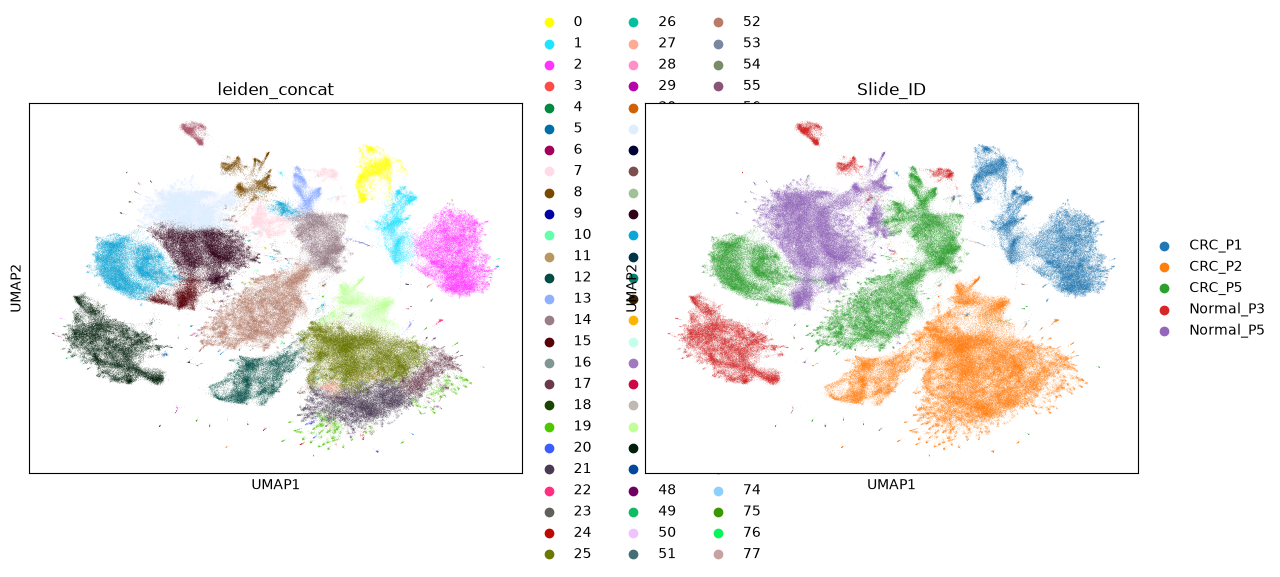

In [12]:
print()
# 6. (Optional) Visualize results using UMAP
sc.tl.umap(adata, neighbors_key="concat_neighbors")
sc.pl.umap(adata, color=["leiden_concat", "Slide_ID"])

In [11]:
n_clusters = adata.obs["leiden_concat"].nunique()
print(f"Number of clusters found: {n_clusters}")

Number of clusters found: 78


In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc

# 2. Subset for sample CRC_P2 (Scanpy automatically subsets obsm["spatial"] too)
test = adata[adata.obs["Slide_ID"] == "CRC_P2"].copy()

fig, ax = plt.subplots(figsize=(10, 10))
sc.pl.spatial(
    test,
    color="leiden_concat",
    spot_size=50,              # Adjust dot size based on cell density
    frameon=False,
    title="CRC_P2: Context-Aware Cell Clusters",
    ax=ax,
    show=True
)

In [ ]:
# LEIDEN JUST ON CELLS
# Use cell-level representations (which are unique per cell)
sc.pp.neighbors(adata, use_rep="X_dae_trans_cell", n_neighbors=15)
sc.tl.leiden(adata, resolution=0.5, key_added="leiden_cell")

print(f"Number of cell-level clusters found: {adata.obs['leiden_cell'].nunique()}")

Number of cell-level clusters found: 36


In [19]:
import numpy as np
import scanpy as sc
from sklearn.decomposition import PCA

# 1. Concatenate cell GNN latents + histology patch latents
X_cell_hist = np.concatenate(
    [trans_sub.obsm["X_dae_trans_cell"], trans_sub.obsm["X_dae_hist_patch"]], 
    axis=1
)
trans_sub.obsm["X_cell_hist"] = X_cell_hist

# 2. Compute PCA directly using Scikit-Learn
pca = PCA(n_components=30, random_state=42)
trans_sub.obsm["X_pca"] = pca.fit_transform(trans_sub.obsm["X_cell_hist"])

# 3. Build neighbor graph using the computed PCA representation
sc.pp.neighbors(trans_sub, use_rep="X_pca", n_neighbors=15)

# 4. Run Leiden clustering
sc.tl.leiden(trans_sub, resolution=0.5, key_added="leiden_cell_hist")

print("Number of context-aware cell clusters:", trans_sub.obs["leiden_cell_hist"].nunique())

Number of context-aware cell clusters: 34


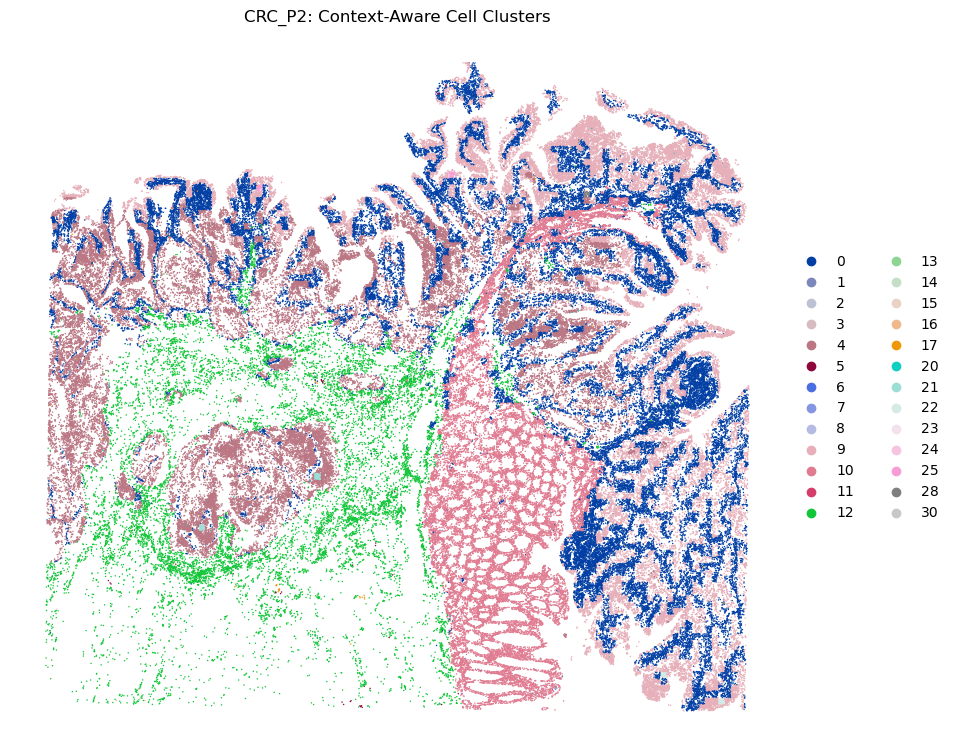

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc

# 1. Ensure cell_xy is stored in obsm BEFORE subsetting
# (extract_cell_xy was already ordered by trans_sub.obs_names in your pipeline!)
trans_sub.obsm["spatial"] = cell_xy

# 2. Subset for sample CRC_P2 (Scanpy automatically subsets obsm["spatial"] too)
test = trans_sub[trans_sub.obs["Slide_ID"] == "CRC_P2"].copy()

# 3. Plot spatial scatter for CRC_P2
fig, ax = plt.subplots(figsize=(10, 10))
sc.pl.spatial(
    test,
    color="leiden_cell_hist",
    spot_size=50,              # Adjust dot size based on cell density
    frameon=False,
    title="CRC_P2: Context-Aware Cell Clusters",
    ax=ax,
    show=True
)

In [34]:
test = ad.read_h5ad(dir_transcriptomics / "count_area_filtered_adata.h5ad")
test


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 456881 × 18085
    obs: 'id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'clusters', 'Slide_ID', 'Patch_ID'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'moranI', 'moranI_pval_fdr', 'spatially_variable', 'highly_variable_n_samples', 'spatially_variable_n_samples', 'gene_selection', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hvg', 'pca', 'pca_loadings_per_sample', 'pca_variance_ratio_per_sample', 'sample_order'
    obsm: 'X_pca', 'X_pca_per_sample_raw', 'spatial'
    varm: 'PCs', 'dispersions_norm_per_sample', 'dispersions_per_sample', 'highly_variable_per_sample', 'log1p_mean_co

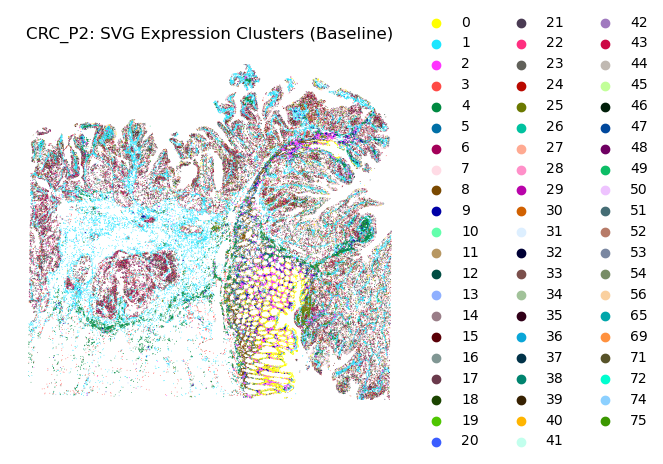

In [36]:
import scanpy as sc

# 1. Filter to SVGs (checking boolean mask cleanly)
if 'spatially_variable_per_sample' in test.varm:
    svg_mask = test.varm['spatially_variable_per_sample'].any(axis=1)
elif 'spatially_variable_n_samples' in test.var:
    svg_mask = test.var['spatially_variable_n_samples'] >= 1
else:
    # Fallback to highly variable genes if spatial column name differs
    svg_mask = test.var['highly_variable']

trans_svg = test[:, svg_mask].copy()

# 2. Compute PCA, Neighbors, and Leiden clustering on SVG expression
sc.pp.pca(trans_svg)
sc.pp.neighbors(trans_svg, n_neighbors=15)
sc.tl.leiden(trans_svg, resolution=0.5, key_added="leiden_svg")

# 3. Assign the cluster labels back to 'test'
test.obs["leiden_svg"] = trans_svg.obs["leiden_svg"]

test2 = test[test.obs["Slide_ID"] == "CRC_P2"].copy()
# 4. Now plot spatially!
sc.pl.spatial(
    test2,
    color="leiden_svg",
    spot_size=50,
    frameon=False,
    title="CRC_P2: SVG Expression Clusters (Baseline)",
    show=True
)

In [39]:
test.obs["clusters"].unique()

['1', '0', '3', '14', '12', ..., '23', '27', '24', '25', '26']
Length: 28
Categories (28, object): ['0', '1', '2', '3', ..., '24', '25', '26', '27']